[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/8_stimulus_features_per_scale.ipynb)

# Stimulus features at each noise level

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Estimate the stimulus features $M^{\rm env}_t(x) = \frac1t\,\mathbb{E}[\mathrm{Cov}(X \mid x_t)]$ at each noise level from the unconditional model, and draw their leading eigenvectors next to those of $M_t(x)$ (notebook 7) for the Inception models of V1 and V4 and the example images of the landing page (task 2 of the note *Scale-resolved decomposition of G(x)*).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), a GPU, and a version of `multigeom` that has `compute_env_per_scale` and `compute_g_per_scale` (newer than 0.1.0.dev4: until it is released, install the package from a clone, see the README).

* **Time**: about 20 min on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

time: <1 sec

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.config": {"load_config": []},
        "multigeom.datasets": {"download_tinyimagenet": [], "load_examples": []},
        "multigeom.diffusion.model": {"build_scheduler": []},
        "multigeom.encoders.receptive_field": {"compute_rf_outline": []},
        "multigeom.pipeline.metric_field": {"load_models": []},
        "multigeom.pipeline.per_scale": {"compute_env": [], "compute_per_scale": []},
        "multigeom.plotting": {"plot_per_scale": []},
        "multigeom.utils": {
            "get_device": [],
            "load_intermediate": [],
            "save_intermediate": [],
        },
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 4.13 s, sys: 211 ms, total: 4.34 s
Wall time: 1.83 s


### 1.2. Imports and parameters

Work from the repository root, import the packages and the helpers of the per-scale analyses (`multigeom.plotting`, `multigeom.analysis` and others in the package), and set the parameters: the encoder, the model of the stimulus statistics, the example images, the samples per noise level, and where the figures go.

<details><summary>Details</summary>

* `load_examples` loads the example images; `compute_env` computes the stimulus features $M^{\rm env}_t(x)$ and `compute_per_scale` the integrand $M_t(x)$ of G(x), at each noise level for each image; `plot_per_scale` draws the figure of one image and returns the data it shows.

</details>

time: 1 sec

In [2]:
%%time

import copy
import os
from pathlib import Path

import matplotlib.pyplot as plt
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet, load_examples
from multigeom.diffusion.model import build_scheduler
from multigeom.encoders.receptive_field import compute_rf_outline
from multigeom.pipeline.metric_field import load_models
from multigeom.pipeline.per_scale import compute_env, compute_per_scale
from multigeom.plotting import plot_per_scale
from multigeom.utils import get_device, load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the encoder, fitted to each of the two areas
    "encoder": "inception",
    "areas": ["V1", "V4"],
    # the area whose diffusion model gives the model of the stimulus statistics (its
    # null token, the unconditional model)
    "prior_area": "V1",
    # the example images of the landing page (https://multigeom.github.io), as in
    # notebook 7: the frog of paper Fig. 3D, then test images by their index among the
    # TinyImageNet validation images in sorted file order
    "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG",
    "test_images": [0, 3, 9, 16, 27, 41, 58, 72, 95, 118, 150, 187],
    # Monte-Carlo samples per noise level: probes for the stimulus features, pairs of
    # responses for M_t(x) (the paper uses 200 for G(x))
    "n_samples": 200,
    # the noisy images per probe and the finite-difference step in units of √t (N_x
    # and η of the note), and the shift of the seeds of the stimulus features, so that
    # their random draws are independent of those of M_t(x)
    "n_noisy": 8,
    "eta": 0.02,
    "env_seed_offset": 100_000,
    # leading eigenvectors kept and drawn at each noise level
    "n_eigvecs": 4,
    # where the figures are saved (one per image), their resolution in the file and
    # where the computed results are stored, so that a new run reloads them in seconds
    # instead of recomputing them (True: recompute and overwrite them)
    "intermediate_dir": "data/02_intermediate/8_stimulus_features_per_scale",
    "recompute": False,
    # on screen, and the images whose figures stay in the notebook (each is about 1 MB)
    "figure_dir": "assets/figures/task2",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["frog"],
}

# the diffusion and estimator configs (packaged with multigeom)
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials
device: cuda
CPU times: user 2.05 ms, sys: 0 ns, total: 2.05 ms
Wall time: 1.98 ms


## 2. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face. The InceptionV3 weights are downloaded by torchvision on first use.

time: <1 sec

In [3]:
%%time

# download the checkpoints into runs/ (files that are already there are kept; the
# archive/ folder of older checkpoints and the retina models, */lorenzi/, are skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns=["archive/*", "*/lorenzi/*"],
)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 36.8 ms, sys: 11 ms, total: 47.8 ms
Wall time: 161 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the example images (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet: the frog and the test images (nothing if already there)
download_tinyimagenet()

# the stored results of this notebook, from the dataset
# steevelaquitaine/multigeom-results, if they are published there; otherwise the
# notebook computes them (no download with PARAMS["recompute"])
from huggingface_hub import snapshot_download as download_results

if not PARAMS.get("recompute", False):  # recomputed anyway otherwise
    try:
        download_results(
            repo_id="steevelaquitaine/multigeom-results",
            repo_type="dataset",
            local_dir="data/02_intermediate",
            allow_patterns=["8_stimulus_features_per_scale/*"],
        )
    except Exception as error:  # not published yet, or offline
        print("stored results not downloaded:", type(error).__name__)

Fetching 0 files: 0it [00:00, ?it/s]

CPU times: user 9.52 ms, sys: 915 μs, total: 10.4 ms
Wall time: 118 ms


## 4. Compute the stimulus features $M^{\rm env}_t(x)$ at each noise level

How uncertain the image remains once it is seen through noise of variance $t$, in each direction of image space, from the statistics of the images alone (no neurons). We estimate it at the 24 noise levels of notebook 7, for each example image, with the unconditional model of the V1 diffusion model, and keep its leading 4 eigenvectors and eigenvalues. The results are stored in `data/02_intermediate/8_stimulus_features_per_scale/` and reloaded on later runs (set `"recompute": True` to recompute them).

<details><summary>Details</summary>

* **Definition.** With $x_t = x + \sqrt{t}\,\epsilon$ the image plus Gaussian noise of variance $t$, and $x, x'$ two images drawn independently from the posterior $p(x \mid x_t)$,
  $$M^{\rm env}_t(x) = \tfrac1t\, \mathbb{E}_{x_t \mid x}\left[\mathrm{Cov}(X \mid x_t)\right] = \tfrac12\, \mathbb{E}\left[\tfrac1t (x - x')(x - x')^\top\right],$$
  task 1 with two posterior samples in place of two responses. By the second-order Tweedie formula, it is the mean Jacobian of the posterior mean, $\mathbb{E}_{x_t \mid x}\left[\partial \hat x(x_t) / \partial x_t\right]$ (variance-exploding coordinates). For exact posteriors, $M_t(x) \le M^{\rm env}_t(x)$: the responses can only tell apart what the noise leaves uncertain.
* **The model of the stimulus statistics.** The null token of the diffusion model fitted to V1: it was trained with 10% of the responses replaced by the null token, so it learned the posterior mean $\hat x(x_t) = \mathbb{E}[x \mid x_t]$ of TinyImageNet.
* **Algorithm** (the note, eq. 5). The Jacobian is never formed. For each of the 200 probes $\xi_s \sim \mathcal{N}(0, I)$ of a noise level, $\Delta_s = \xi_s - \frac{1}{2\eta} \frac{1}{N_x} \sum_i [\epsilon_\theta(x_t^{(i)} + \sqrt{\bar\alpha}\, h\, \xi_s) - \epsilon_\theta(x_t^{(i)} - \sqrt{\bar\alpha}\, h\, \xi_s)] \approx M^{\rm env}_t \xi_s$, a central finite difference with $h = \eta\sqrt{t}$ ($\eta = 0.02$), averaged over $N_x = 8$ noisy images. The rows $\Delta_s / \sqrt{N}$ of one level form $D$, so $D^\top D \approx (M^{\rm env}_t)^2$: the right singular vectors of $D$ are the eigenvectors, and its singular values (not squared) the eigenvalues. This is `multigeom.compute_env_per_scale`.
* **Accuracy.** At coarse levels ($\tau \ge 3.2$) the estimate is stable: for the frog, the leading eigenvectors of two runs with different seeds agree with $|\cos| \ge 0.93$. At fine levels, $M^{\rm env}_t$ is close to the identity in most directions (the noise is small compared with how images vary), so its leading eigenvectors are not defined, and 200 probes in 4096 dimensions inflate its eigenvalues: the identity would come out near $\sqrt{4096/200} \approx 4.5$. For the frog, the two runs disagree completely below $\tau = 0$ (alignment of their top-4 eigenvectors ≤ 0.1), and the eigenvalues reach 3.5 at the finest level. Read the fine levels of the stimulus features as unreliable.

</details>

time: 13 min

In [5]:
%%time

# 1. estimator settings: those of the paper, with n_samples samples per noise level
# (probes here, pairs of responses for M_t(x)), and the n_eigvecs leading eigenpairs
cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = PARAMS["n_samples"]
cfg.top_k = PARAMS["n_eigvecs"]

# 2. the example images with their seeds, and the noise schedule (the ᾱ of each step)
examples = load_examples(PARAMS, int(cfg.seed))
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 3. the stimulus features of every image, from the null token of the diffusion model
# of prior_area; env[name] holds tau = log t, the eigenvalues and the eigenvectors
env_file = Path(PARAMS["intermediate_dir"]) / "stimulus_features.pt"
if env_file.exists() and not PARAMS["recompute"]:
    env = load_intermediate(env_file)
else:
    _, prior_unet, _ = load_models(
        PARAMS["encoder"],
        PARAMS["prior_area"],
        Path("runs"),
        None,
        diff_cfg,
        True,
        device,
    )
    env = compute_env(examples, prior_unet, alphas_cumprod, cfg, device, PARAMS)
    save_intermediate(env, env_file)
print("stimulus features done:", len(env), "images")

stimulus features done: 13 images
CPU times: user 14min 1s, sys: 632 ms, total: 14min 2s
Wall time: 14min 1s


## 5. Compute $M_t(x)$ at each noise level

The integrand of G(x) for V1 and V4, as in notebook 7 (same settings and seeds, so the same results).

time: 5 min

In [6]:
%%time

# M_t(x) of every image for each area; results[area][name] holds tau = log t, the
# eigenvalues and the eigenvectors
# outlines[area] holds the region of the image its neurons cover
areas_file = Path(PARAMS["intermediate_dir"]) / "areas.pt"
if areas_file.exists() and not PARAMS["recompute"]:
    results, outlines = load_intermediate(areas_file)
else:
    results, outlines = {}, {}
    for area in PARAMS["areas"]:
        encoder, unet, _ = load_models(
            PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
        )
        results[area] = compute_per_scale(
            examples, encoder, unet, alphas_cumprod, cfg, device
        )
        outlines[area] = compute_rf_outline(encoder.state_dict())
        print(area, "done:", len(results[area]), "images")
    save_intermediate((results, outlines), areas_file)

V1 done: 13 images


V4 done: 13 images
CPU times: user 4min 20s, sys: 1min 13s, total: 5min 34s
Wall time: 5min 32s


## 6. Plot the stimulus features next to $M_t(x)$ at each noise level

One figure per image, saved to `assets/figures/task2/stimulus_features_per_scale_<image>.png`; to keep the notebook small, it shows only those of the images in `PARAMS["show"]` (the frog). Each figure has the image (A), the leading 4 eigenvectors of the stimulus features $M^{\rm env}_t(x)$ (B), and those of $M_t(x)$ for V1 (C) and V4 (D), from the finest noise level (left) to the coarsest (right); then the eigenvalues of the stimulus features (E), and those of V1 and V4, each area over its largest leading eigenvalue (F).

<details><summary>Details</summary>

* Each eigenvector is drawn like those of Fig. 3E: red positive, blue negative, scaled to its own 99th percentile of |v|. Its sign, arbitrary, agrees with the same eigenvector at the next coarser level (notebook 7).
* The coloured outlines mark the region of the image that the neurons of each area cover on the image, on the tiles of their area and, both, on those of the stimulus features (V1 blue, V4 orange; the contour at half the largest of their Gaussian readouts, as in Fig. 3D): the eigenvectors matter there, where the areas see the image.
* In E and F, the leading eigenvalue of each matrix is thick and the next three are thin, on linear axes. At fine levels the eigenvalues of the stimulus features are inflated (details of section 4), so they are drawn as they are, in their own panel; in F, all the eigenvalues of an area are divided by the largest of its leading ones, so V1 and V4 compare by where along $\tau$ they sit.

</details>

time: 22 secs

13 figures saved in assets/figures/task2
CPU times: user 40.1 s, sys: 1.96 s, total: 42 s
Wall time: 39.7 s


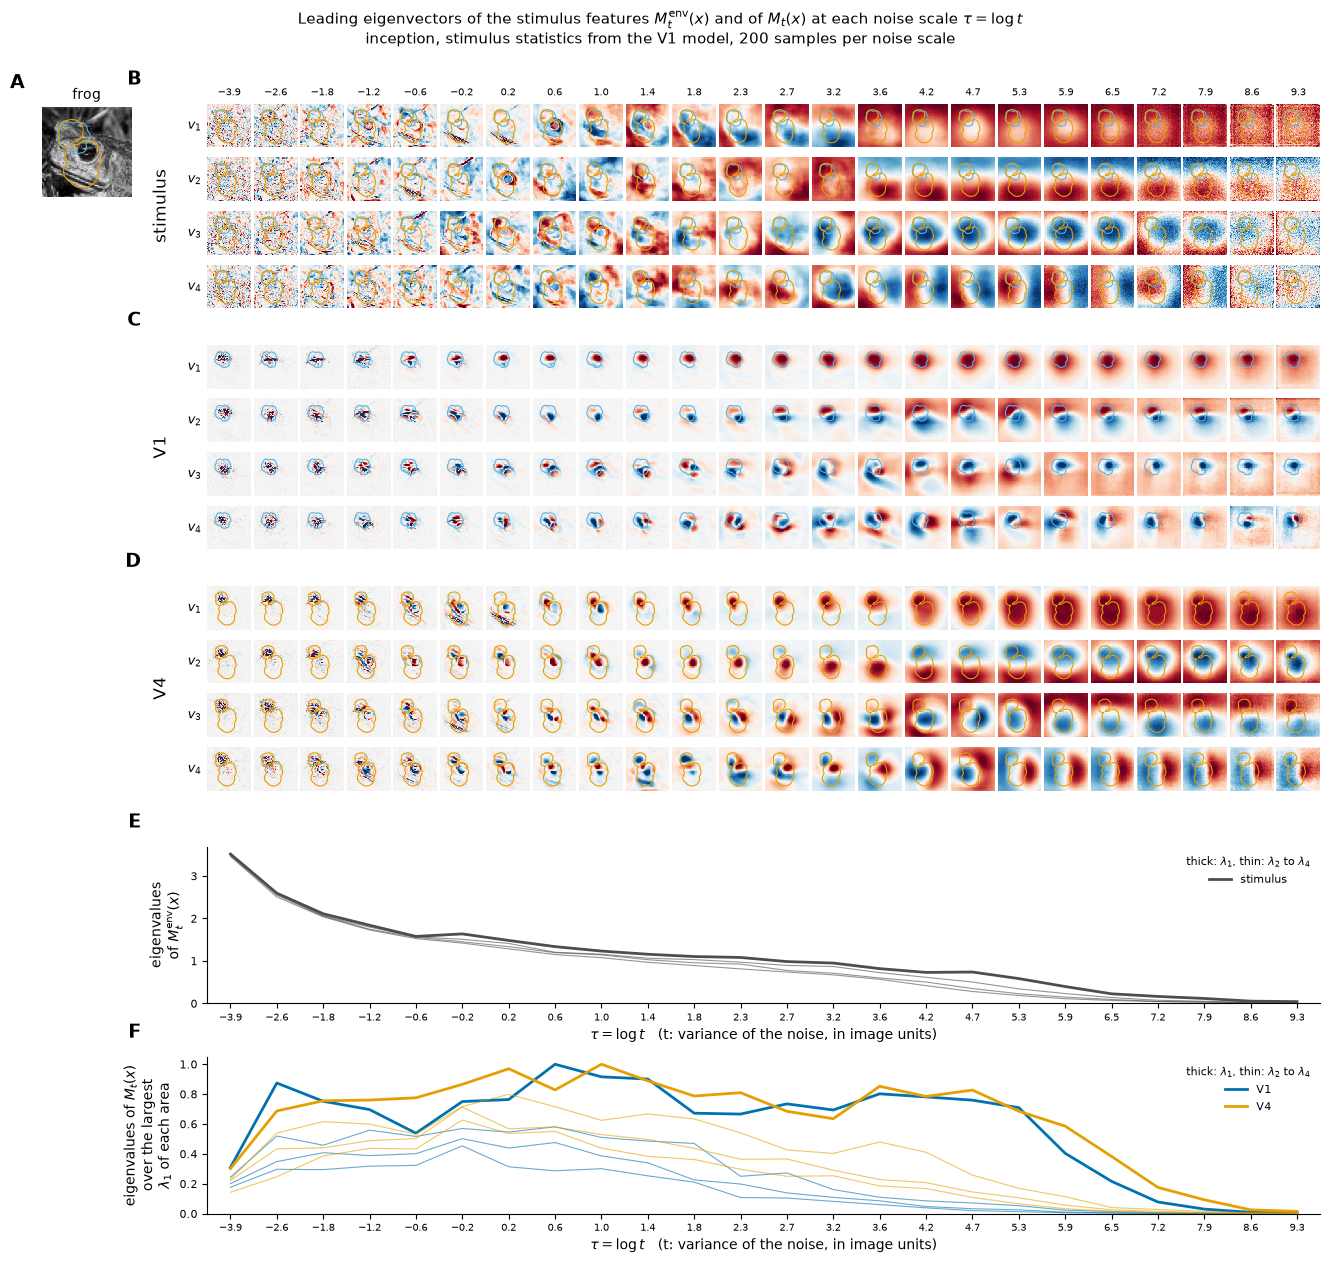

In [7]:
%%time

# 1. the folder of the figures, and the title of every figure
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
suptitle = (
    r"Leading eigenvectors of the stimulus features $M_t^{\rm env}(x)$ and of $M_t(x)$"
    r" at each noise scale $\tau = \log t$"
    f"\n{PARAMS['encoder']}, stimulus statistics from the {PARAMS['prior_area']} model,"
    f" {PARAMS['n_samples']} samples per noise scale"
)

# 2. one figure per image, the stimulus features above the areas: draw it, keep the
# data it shows, and save it; only the figures of the images in PARAMS["show"] stay in
# the notebook
plotted = {}
for name, (image, _) in examples.items():
    records = {"stimulus": env[name]}
    records.update({area: results[area][name] for area in PARAMS["areas"]})
    fig, plotted[name] = plot_per_scale(
        image, records, PARAMS, name, suptitle, outlines
    )
    fig.savefig(
        figure_dir / f"stimulus_features_per_scale_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)

# 3. where the figures are
print(len(plotted), "figures saved in", figure_dir)

## 7. Conclusion

* **What we computed.** The stimulus features $M^{\rm env}_t(x)$ at the 24 noise levels of notebook 7, for the 13 example images of the landing page, from the unconditional model of the V1 diffusion model (200 probes per level, each over 8 noisy images: 13 min on one GPU), next to $M_t(x)$ of V1 and V4 (5 min). The figures are in `assets/figures/task2/`.
* **What the stimulus features look like.** In the figures of the frog and of img0072, at coarse noise levels ($\tau \gtrsim 4.7$) they are smooth patterns over the whole image (its overall brightness, a gradient from top to bottom or from left to right, a central blob), much like the principal components of natural images; at intermediate levels ($\tau \approx 0$ to 3) they follow the contours of the image; at fine levels they are not defined (details of section 4). The eigenvectors of $M_t(x)$, by contrast, stay on the receptive fields of the model at every level.
* **Eigenvalues.** In panel E of the frog, the eigenvalues of the stimulus features fall from about 3.5 at the finest level to about 0.05 at the coarsest; their values above 1 at fine levels come from the 200 probes, not from the images. They lie one to two orders of magnitude above those of V1 and V4 (about 0.1 at most, notebook 7), as $M_t(x) \le M^{\rm env}_t(x)$ requires. In panel F, normalized, the eigenvalues of V4 fall more slowly than those of V1 at coarse levels.
* **Caveats.** The fine levels of the stimulus features ($\tau < 0$) are not reproducible from one seed to the next. At the coarsest levels ($\tau \ge 7.9$) their eigenvectors look grainy: $M^{\rm env}_t$ is small there, and averaging the finite differences over 8 noisy images per probe leaves noise. The stimulus statistics come from the null token of the V1 model only; that of the V4 model should give the same, which we did not check.
* **Next steps.** Task 3 of the note: the envelope spectrum $\rho^{\rm env}(\tau) = \mathbb{E}\left[\frac1t \lVert \hat x(x_t) - x \rVert^2\right]$, which is the trace of $M^{\rm env}_t(x)$ averaged over the images (the probes of this notebook estimate that trace without bias, $\frac1N \sum_s \xi_s^\top \Delta_s$); then task 4, the coding spectrum $\rho(\tau)$ and $\tfrac12 \int \rho\, d\tau = I(R; X)$.